In [2]:
%matplotlib inline
%load_ext autoreload
%autoreload 2

In [3]:
from pathlib import Path
import pandas as pd
from matplotlib import pyplot as plt
import numpy as np
import pickle
from src.utils import pmf_utils

from notebooks.imports import *

### Config

In [4]:
from config import dir_config

raw_dir = Path(dir_config.data.raw)
processed_dir = Path(dir_config.data.processed)

me_type = "global"

## Helper Functions

In [5]:
# Define mapping from pulse_type to descriptive variable names
pulse_mapping = {
    -3: "late_left_pulse",
    -2: "middle_left_pulse",
    -1: "early_left_pulse",
    0: "control",
    1: "early_right_pulse",
    2: "middle_right_pulse",
    3: "late_right_pulse",
}

def get_pulse_data(data, pulse_type):
    pulse_data = data[(data.pulse_type == pulse_type)]
    if pulse_type > 0:
        # include positive 100 control data too
        positive_control_data = data[(data.pulse_type == 0) & (data.signed_coherence == 100)]
        pulse_data = pd.concat([pulse_data, positive_control_data])
    elif pulse_type < 0:
        negavtive_control_data = data[(data.pulse_type == 0) & (data.signed_coherence == -100)]
        pulse_data = pd.concat([pulse_data, negavtive_control_data])
    return pulse_data.copy()

def get_pulse_coh_indices(data):
    # note indices for each pulse_type and each signed_coherence under each pulse_type
    pulse_type = data.pulse_type.unique()
    pulse_data = get_pulse_data(data, pulse_type)
    indices = {}
    for pt in pulse_type:
        indices[pt] = {}
        for sc in pulse_data.signed_coherence.unique():
            indices[pt][sc] = pulse_data[pulse_data.signed_coherence == sc].agg_code.values


### Load and Preprocess data

In [6]:
# with open(Path(processed_dir, f"motion_energies_normalized/me_{me_type}.pkl"), "rb") as f:
#     motion_energy_dict = pickle.load(f)
# print(len(motion_energy_dict))

data = pd.read_csv(Path(processed_dir, "valid_data.csv"), index_col=None)
# valid_data.to_csv(Path(processed_dir, "valid_data.csv"), index=False)

data.reaction_time = (data.reaction_time * 1000).astype(int)
# data = data[data.reaction_time < 3000]
data

,agg_code,idx_session,data_source,subject_id,session_id,idx_valid_trial,idx_correction,is_correction_trial,signed_coherence,target,choice,reaction_time,outcome,reward_amount,fixation_duration,stimulus_duration,reinforcement_duration,intertrial_delay,stimulus_seed,is_pulse_trial,pulse_onset,pulse_duration,pulse_coherence,pulse_type
0,DBM12_6_1_1,32,uw,DBM12,6_1,1,0,False,100,1.0,0,810,0.0,NaN,0.626644,25.0,0.0,4.245489,915716,False,0.416750,0.066680,100.0,0
1,DBM12_6_1_2,32,uw,DBM12,6_1,2,0,False,100,1.0,1,1197,1.0,1.5,0.546771,25.0,0.0,0.500000,830639,False,0.050010,0.066680,100.0,0
2,DBM12_6_1_3,32,uw,DBM12,6_1,3,0,False,-100,-1.0,0,459,1.0,1.5,0.889096,25.0,0.0,0.500000,14826,False,0.416750,0.066680,-100.0,0
3,DBM12_6_1_4,32,uw,DBM12,6_1,4,0,False,-100,-1.0,0,446,1.0,1.5,0.515926,25.0,0.0,0.500000,921577,False,0.050010,0.066680,-100.0,0
4,DBM12_6_1_5,32,uw,DBM12,6_1,5,0,False,-100,-1.0,0,398,1.0,1.5,0.540356,25.0,0.0,0.500000,111085,False,0.416750,0.066680,-100.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
25503,PSUIM7_9_1_613,290,ucla,PSUIM7,9_1,613,0,False,9,1.0,1,1899,1.0,1.5,1.000000,60.0,0.5,0.250000,613,False,NaN,NaN,NaN,0
25504,PSUIM7_9_1_615,290,ucla,PSUIM7,9_1,615,0,False,100,1.0,1,3865,1.0,1.5,1.000000,60.0,0.5,0.250000,615,False,NaN,NaN,NaN,0
25505,PSUIM7_9_1_617,290,ucla,PSUIM7,9_1,617,0,False,18,1.0,0,950,0.0,0.0,1.000000,60.0,1.5,0.809093,617,False,NaN,NaN,NaN,0
25506,PSUIM7_9_1_619,290,ucla,PSUIM7,9_1,619,0,False,-36,-1.0,0,1200,1.0,1.5,1.000000,60.0,0.5,0.250000,619,True,0.242148,0.050971,-100.0,-2


## Acccuracy vs Reaction Time

In [7]:
smoothing_window = 400

In [8]:
import pandas as pd


def bin_accuracy(data, bin_width=100):
    # Compute bins using numpy
    bins = np.arange(0, 10000, bin_width)

    # Use np.digitize for faster binning of reaction times
    bin_indices = np.digitize(data.reaction_time, bins, right=False) - 1  # Subtract 1 to get the correct bin index

    # Add the bin index to the data
    data["bin"] = bin_indices

    # Calculate the mean outcome for each bin
    binned_accuracy = data.groupby("bin")["outcome"].mean().reset_index()

    # Calculate midpoints using bins directly (without applying lambda function)
    binned_accuracy["midpoint"] = bins[binned_accuracy["bin"]] + bin_width / 2

    return binned_accuracy

# get binned trials
def get_binned_trials(data, bin_width=100):
    # Compute bins using numpy
    bins = np.arange(0, 10000, bin_width)

    # Use np.digitize for faster binning of reaction times
    bin_indices = np.digitize(data.reaction_time, bins, right=False) - 1  # Subtract 1 to get the correct bin index

    binned_trials = {}
    for bin_idx in np.unique(bin_indices):
        binned_trials[bin_idx] = data[bin_indices == bin_idx]

    return binned_trials


def get_abs_coherence_accuracy(data):
    coherence_levels = sorted(np.abs(data.signed_coherence).unique())
    accuracy = []
    trials = []
    for coh in coherence_levels:
        coh_data = data[np.abs(data.signed_coherence) == coh]
        acc = coh_data.outcome.mean()
        accuracy.append(acc)
        trials.append(len(coh_data))
    return np.array(coherence_levels), np.array(accuracy), np.array(trials)

def fit_weibull_psychometric(data):
    from scipy.optimize import curve_fit

    x, y, trials = get_abs_coherence_accuracy(data)

    def weibull(x, alpha, beta, gamma, delta):
        return gamma + (1 - gamma - delta) * (1 - np.exp(-(x / alpha) ** beta))

    # Initial parameter guesses
    initial_params = [np.median(x), 2.0, 0.0, 0.0]

    sigma = 1/np.sqrt(trials)

    # Fit the Weibull function to the data
    params, _ = curve_fit(weibull, x, y, p0=initial_params, sigma=sigma, bounds=(0, [np.inf, np.inf, 1, 1]))

    return params

### Perfect Accumulator - Discrimination Threshold

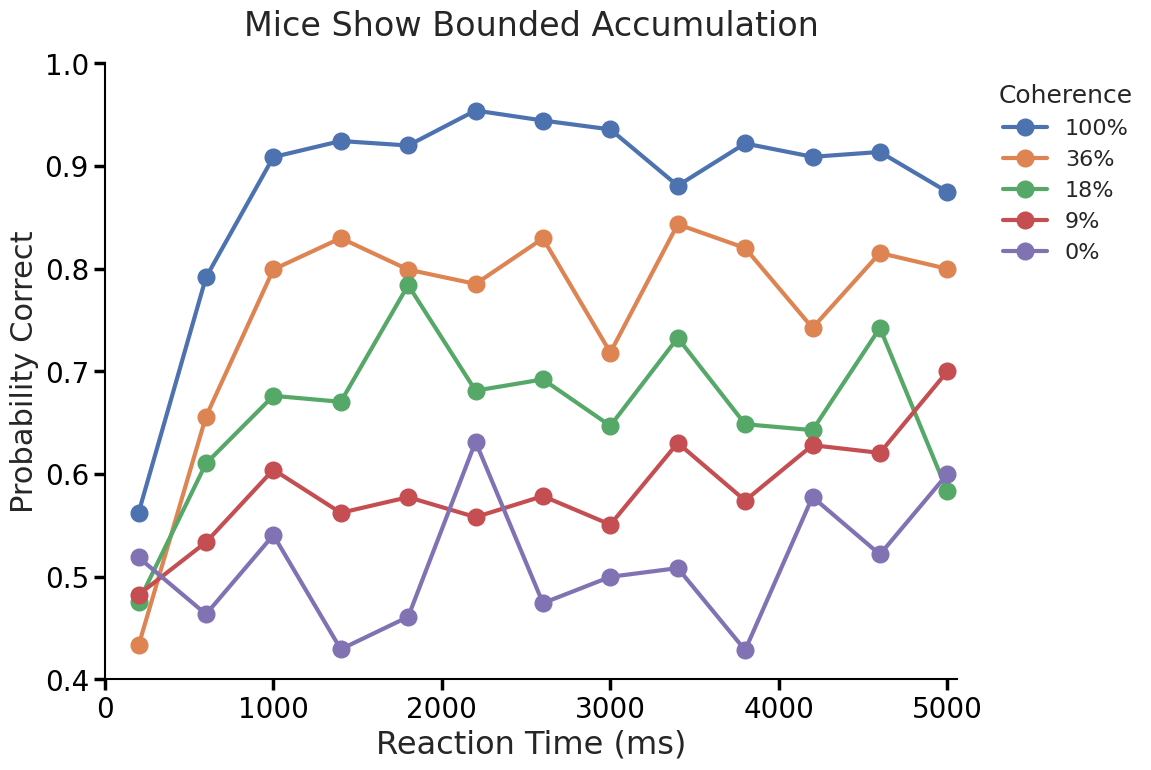

In [11]:
smoothing_window = 400

# Filter control data safely
control = get_pulse_data(data, pulse_type=0)

# Add absolute coherence
control.loc[:, "absolute_coherence"] = control["signed_coherence"].abs()

# Compute binned accuracy per absolute coherence level
binned_accuracies = {}
for coh in control["absolute_coherence"].unique():
    coherence_data = control[control["absolute_coherence"] == coh].copy()
    binned_accuracies[coh] = bin_accuracy(coherence_data, bin_width=smoothing_window)

# Plot
plt.figure(figsize=(11, 8))
for coh, binned_accuracy in binned_accuracies.items():
    plt.plot(binned_accuracy["midpoint"], binned_accuracy["outcome"], marker="o", ms=12, lw=3, label=f"{coh}%")

plt.xticks(np.arange(0,5001,1000), color='black', fontsize=16)

plt.yticks(np.arange(0.4, 1.1, 0.1), color="black", fontsize=16)
plt.xlabel("Reaction Time (ms)", fontsize=23)
plt.ylabel("Probability Correct", fontsize=22)
plt.title("Mice Show Bounded Accumulation", fontsize=24, pad=20)
plt.grid(False)
plt.gca().spines['right'].set_visible(False)
plt.gca().spines['top'].set_visible(False)
for dir in ['left', 'bottom']:
    plt.gca().spines[dir].set_linewidth(1.5)
    plt.gca().spines[dir].set_color('black')

plt.ylim(0.4, 1)
plt.xlim(0, 5060)

plt.legend(title="Coherence", bbox_to_anchor=(1.025, 1), loc="upper left", fontsize=16, frameon=False, title_fontsize=18)

plt.tick_params( axis="both", which="major", labelsize=20, width=2.5, length=8, color="black", direction="out", bottom=True, left=True)


plt.savefig(Path(dir_config.project_dir, "dissemination", "poster", "accuracy_vs_rt_control.svg"), bbox_inches='tight')
plt.savefig(Path(dir_config.project_dir, "dissemination", "poster", "accuracy_vs_rt_control.png"), bbox_inches="tight")


plt.show()

### Click rate Reliability (onset reliability index)

In [9]:
dir_config.project_dir


'/src'

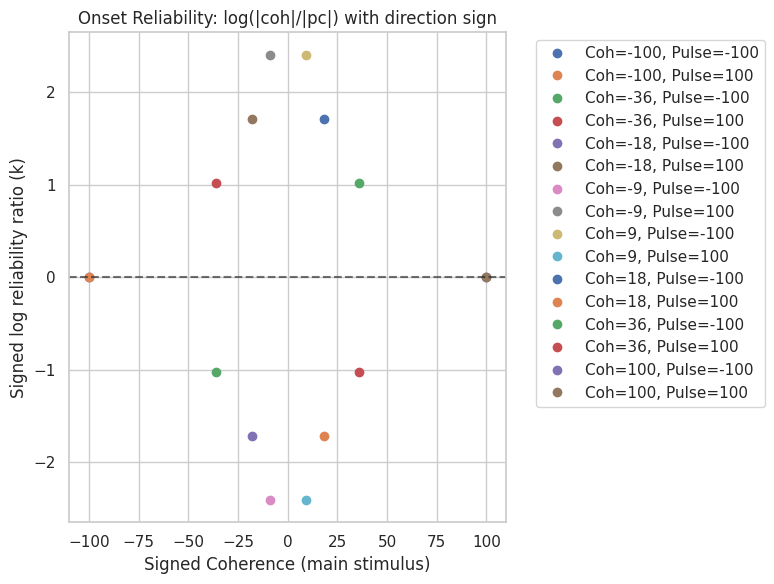

In [45]:
import numpy as np
import matplotlib.pyplot as plt

coherences = np.array([-100, -36, -18, -9, 0, 9, 18, 36, 100])
pulse_cohs = np.array([-100, 100])

plt.figure(figsize=(8, 6))

for coh in coherences:
    if coh == 0 or np.isnan(coh):
        continue  # skip zero since reliability undefined
    for pc in pulse_cohs:
        # compute signed log-ratio of reliabilities
        k = np.sign(coh * pc) * np.log(abs(coh) / abs(pc))
        plt.plot(coh, k, "o", label=f"Coh={coh}, Pulse={pc}")

plt.axhline(0, color="k", linestyle="--", alpha=0.6)
plt.xlabel("Signed Coherence (main stimulus)")
plt.ylabel("Signed log reliability ratio (k)")
plt.title("Onset Reliability: log(|coh|/|pc|) with direction sign")
plt.legend(bbox_to_anchor=(1.05, 1), loc="upper left")
plt.tight_layout()
plt.show()


Fitted gamma: 1.579
Scale a: 9.170300781900666 Intercept b: 0.6256382585074132 SSE: 0.20944373579533984


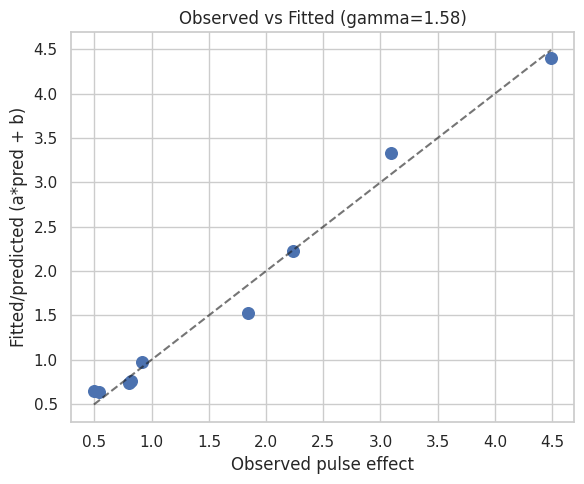

   coh    pc  observed  pred_mag
0  0.1  0.05  0.805365  0.012539
1  0.1  0.15  1.845192  0.098221
2  0.1  0.45  4.492128  0.411703
3  0.3  0.05  0.494492  0.002788
4  0.3  0.15  0.916853  0.037616
5  0.3  0.45  3.092771  0.294662
6  0.6  0.05  0.539090  0.000969
7  0.6  0.15  0.823068  0.015112
8  0.6  0.45  2.235645  0.174758


In [46]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# -----------------------------------------------------------------------------
# Helpers: predicted pulse weight and effect
# -----------------------------------------------------------------------------
def pulse_weight(coh, pc, gamma=1.0, eps=1e-12):
    # coh and pc must be positive magnitudes (use absolute coherences)
    # add eps to avoid division by zero
    coh = np.asarray(coh) + eps
    pc = np.asarray(pc) + eps
    return (pc**gamma) / (pc**gamma + coh**gamma)


def predicted_effect(coh, pc, gamma=1.0):
    """Predicted (signed) pulse effect magnitude before scaling.
    Use absolute magnitudes for reliability weighting; keep sign from pulse (or combine separately)."""
    w = pulse_weight(np.abs(coh), np.abs(pc), gamma=gamma)
    # raw direction: if your pulse has sign different than coh, you could route sign separately.
    # here we return magnitude of predicted influence; user can multiply by sign of pulse if needed.
    return w * pc


# -----------------------------------------------------------------------------
# Fit gamma by grid search + linear scaling (a, b) to map pred -> observed
# -----------------------------------------------------------------------------
def fit_gamma_by_grid(observed, coh, pc, gammas=None):
    """Find the gamma that minimizes SSE after fitting a linear scaling (a,b)
    Observed, coh, pc are 1D arrays aligned trial-by-trial or condition-by-condition.
    Returns dict with best gamma, best scale/intercept, and fit diagnostics.
    """
    observed = np.asarray(observed)
    coh = np.asarray(coh)
    pc = np.asarray(pc)
    if gammas is None:
        gammas = np.linspace(0.1, 3.0, 61)  # adjust range if needed

    best = {"gamma": None, "a": None, "b": None, "sse": np.inf, "pred": None}
    for g in gammas:
        pred = predicted_effect(coh, pc, gamma=g)
        # Fit linear mapping observed ≈ a * pred + b
        X = np.vstack([pred, np.ones_like(pred)]).T
        # Solve least-squares
        a, b = np.linalg.lstsq(X, observed, rcond=None)[0]
        fitted = a * pred + b
        sse = np.sum((observed - fitted) ** 2)
        if sse < best["sse"]:
            best.update({"gamma": g, "a": a, "b": b, "sse": sse, "pred": pred.copy(), "fitted": fitted})
    return best


# -----------------------------------------------------------------------------
# Small synthetic example to illustrate usage
# -----------------------------------------------------------------------------
def example_synthetic():
    # simulate some condition-level observed pulse effects
    # Suppose we have 9 condition cells: 3 coh levels × 3 pulse strengths
    coh_levels = np.array([0.1, 0.3, 0.6])
    pc_levels = np.array([0.05, 0.15, 0.45])
    rows = []
    for coh in coh_levels:
        for pc in pc_levels:
            # true gamma = 1.2, true scale a = 10, intercept b = 0.5, plus noise
            true_gamma = 1.2
            true_a = 10.0
            true_b = 0.5
            pred = predicted_effect(coh, pc, gamma=true_gamma)
            obs = true_a * pred + true_b + np.random.normal(scale=0.2)
            rows.append({"coh": coh, "pc": pc, "observed": obs})
    df = pd.DataFrame(rows)

    # Fit gamma
    best = fit_gamma_by_grid(df["observed"].values, df["coh"].values, df["pc"].values, gammas=np.linspace(0.1, 3.0, 101))

    print("Fitted gamma:", best["gamma"])
    print("Scale a:", best["a"], "Intercept b:", best["b"], "SSE:", best["sse"])

    # Plot observed vs predicted (with best gamma)
    plt.figure(figsize=(6, 5))
    plt.scatter(df["observed"], best["fitted"], s=70)
    mn = min(df["observed"].min(), best["fitted"].min())
    mx = max(df["observed"].max(), best["fitted"].max())
    plt.plot([mn, mx], [mn, mx], "k--", alpha=0.6)
    plt.xlabel("Observed pulse effect")
    plt.ylabel("Fitted/predicted (a*pred + b)")
    plt.title(f"Observed vs Fitted (gamma={best['gamma']:.2f})")
    plt.tight_layout()
    plt.show()

    # Also show predicted weights heatmap-like table
    df["pred_mag"] = best["pred"]
    print(df)


# run example
example_synthetic()
